# 學生學習與作業版｜任務 4：描述統計與視覺化

**姓名：**劉羿岑　**學號／組別：**C114118115　**完成日期：**2026/11/12

**學習目標：** 以描述統計、直方圖和盒鬚圖理解分布與離群值。

本單元與教師版「任務 4」相同標題、資料、教學順序與範例；除了明確標示的作業與填空，其餘教師版教材內容保留。對照重點：程式填空對應教師版「4.2 直方圖」。

### 如何完成
1. 先閱讀觀念與執行資料準備；各單元可以獨立啟動，不需要依賴上一單元的變數。
2. **💻 P 作業**：在指定程式 cell 補上 `____`，可先用提供的 Vibe Coding 提示詞詢問 AI。補完再執行，並執行後面的驗證 cell。未填時出現 `NameError` 是預期現象，先完成填空再繼續。
3. **📝 Q 作業**：查詢 AI、比較教材內容，填寫緊接的文字作答區；請記錄實際提示詞、自己的解釋與查證方式。
4. **🎯 M 小任務**：在任務 4、8、12、16 將前面幾單元整合成可執行的成果。不要只交 AI 回覆，要交實際程式、輸出與自己的解釋。
5. 把 Notebook 存到自己的 Google 雲端硬碟，完成後下載／依教師指示繳交 `.ipynb`；小任務保留輸出、文字與 AI 使用紀錄。

**案例限制：**本資料是公式生成的 60 筆模擬紀錄，不能推論真實學生或因果。缺失與 15 小時值在計分後加入。預測時欄位可得性是假設；全部資料已在前半段探索，後續切出的測試集僅示範流程，不能視為完全獨立的新資料。

**完成檢核：**本單元有 1 項程式填空、2 項 AI 查詢作答；若是任務 4、8、12、16，另外有 1 項整合小任務。請保留自己的輸出、回答和驗證紀錄。


## 共用資料準備
以下在記憶體重建與既有教材相同的資料。執行後可以直接開始本單元；不會覆寫 CSV。


In [10]:
# 匯入套件：numpy 建立隨機資料，pandas 管理表格，pyplot 繪圖
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# 固定種子，並維持呼叫順序，以重現原教材的 60 筆模擬資料
rng = np.random.default_rng(42)
n = 60
departments = ["資訊管理", "企業管理", "金融管理"]
# 每個字典鍵是一個欄位；對應的值是 60 名學生的資料
data = {
    "student_id": range(1, n + 1),
    "department": rng.choice(departments, n),
    "sleep_hours": rng.normal(6.7, 1.1, n).round(1),
    "screen_time_hours": rng.normal(5.0, 1.5, n).clip(1, 10).round(1),
    "study_hours": rng.normal(2.5, 1.0, n).clip(0.5, 6).round(1),
    "attendance_rate": rng.normal(88, 8, n).clip(60, 100).round(0),
}
df = pd.DataFrame(data)
# 成績依設定公式與隨機誤差建立；關係來自模擬規則，不能視為因果發現
noise = rng.normal(0, 5, n)
score = (50 + 3 * df["study_hours"] + 2 * df["sleep_hours"]
         - 1.2 * df["screen_time_hours"] + 0.15 * df["attendance_rate"] + noise)
df["quiz_score"] = score.clip(0, 100).round(0)
# 故意在計分後加入資料品質問題；無法從表格還原計分時原始值
df.loc[[5, 17], "sleep_hours"] = np.nan
df.loc[8, "screen_time_hours"] = 15.0
print("模擬資料形狀（列, 欄）：", df.shape)

模擬資料形狀（列, 欄）： (60, 7)


## 4.1 描述統計
**觀念說明：**count 是非缺失筆數，mean 是平均，50% 是中位數。極端值可能影響平均，不能只看單一統計量。


In [11]:
# describe 彙整筆數、平均、標準差、四分位數與最大最小值
display(df[["quiz_score", "sleep_hours", "screen_time_hours"]].describe())
print("總筆數：", len(df), "睡眠有效筆數：", df["sleep_hours"].count())
print("螢幕時間平均／中位數：", df["screen_time_hours"].mean(), df["screen_time_hours"].median())


,quiz_score,sleep_hours,screen_time_hours
count,60.000000,58.000000,60.000000
mean,78.800000,6.682759,4.946667
std,6.681114,0.822307,1.985239
min,63.000000,4.800000,1.800000
25%,75.000000,6.200000,3.600000
50%,80.000000,6.750000,4.700000
75%,82.250000,7.300000,5.625000
max,92.000000,9.100000,15.000000


總筆數： 60 睡眠有效筆數： 58
螢幕時間平均／中位數： 4.946666666666668 4.7


## 📝 學生作業 04-Q1｜AI 查詢與作答：統計量
**任務：**平均數與中位數如何受到極端值影響？以具體數字說明。

**可使用的 AI 提示詞：**
```text
我是 Python 與資料分析初學者。請用少量數字示範平均數與中位數，加入極端值前後各算一次，並說明限制。
請使用繁體中文、台灣常用名詞，分步解釋，並提出我可以自行驗證的一個例子；不要假設我的程式輸出。
```
先閱讀教材，再詢問 AI。請記錄工具名稱、實際提示詞；若 AI 提供資料來源，記錄可查證的網址／文件名稱與日期，並自行檢查，無法查證時寫「尚未查證」。不要提供真實個資。


### ✍️ 作業 04-Q1 專用作答區：請雙擊此文字儲存格填寫
- AI 工具及實際提示詞：無
- AI 回答重點（請自行整理）：無
- 我的理解與具體例子：平均數較會受到極端值影響，舉例一組簡單的資料10,20,30,40,50，平均數是將所有數字相加除以個數=30，中位數是將資料由小到大排序後，位於正中間的數=30。如果在資料中加入一個極大值1000，資料變成：10,20,30,40,50,1000，平均數=191.67。但中位數因為不考慮數值之間的具體差距或總量，可能遺漏重要的分佈資訊
- 查證來源／方式及日期（無法查證請註明）：https://allaboutdataanalysis.medium.com/%E5%AD%B8%E6%9C%83%E9%80%99%E5%80%8B%E6%9C%80%E5%9F%BA%E7%A4%8E%E7%9A%84%E7%B5%B1%E8%A8%88%E5%AD%B8%E7%9F%A5%E8%AD%98-%E8%B3%87%E6%96%99%E5%88%86%E6%9E%90%E5%B0%88%E6%A5%AD%E5%BA%A6%E6%8F%90%E5%8D%87%E4%B8%80%E5%A4%A7%E6%88%AA-7ff00017191d Apr 20, 2020
https://www.jmp.com/zh-hant/statistics-knowledge-portal/measures-of-central-tendency-and-variability/mean-median-and-mode
- 我檢查或修正 AI 回答的地方：無


## 4.2 直方圖
橫軸是分數區間，縱軸為該區間人數。調整 bins 會改變切分方式，不會改變資料；比較不同圖前確認尺度與分箱。


## 💻 學生作業 04-P1｜Vibe Coding 程式填空
**對應教師版：**任務 4「4.2 直方圖」的示範程式。

**任務：**在既有圖表中繪製 quiz_score 的直方圖，排除缺失值，分成 10 箱，保留既有標題和座標軸。

**執行方式：**找到下一個程式儲存格中的 `____`，使用自己撰寫或 AI 建議的程式補齊，保留其他已提供的程式與註解。補完後先執行該 cell，再執行緊接的自動檢查；後續單元內容可能依賴此變數。

**可使用的 Vibe Coding 提示詞：**
```text
我是 Python 與資料分析初學者，正在 Google Colab 使用 pandas、numpy、matplotlib 或 scikit-learn。
我的任務是：在既有圖表中繪製 quiz_score 的直方圖，排除缺失值，分成 10 箱，保留既有標題和座標軸。
請依我貼上的上下文，只協助補上 ____，保留指定變數名稱與後續程式，不修改原始 df。
請解釋每一步的作用，提供繁體中文註解及可手動驗證的方法。
不要虛構執行結果；如需額外資訊，先指出缺少什麼。
```
完成後記錄實際使用的提示詞與自己改動的地方。


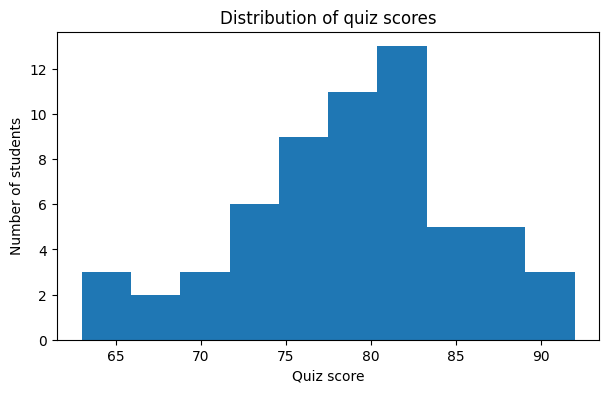

有效成績筆數： 60


In [12]:
# 以英文標籤避免 Colab 缺中文字型；圖形後呼叫 show
plt.figure(figsize=(7, 4))
plt.hist(df["quiz_score"].dropna(), bins=10)  # TODO：以 quiz_score 的非缺失資料畫 bins=10 的直方圖
plt.title("Distribution of quiz scores")
plt.xlabel("Quiz score")
plt.ylabel("Number of students")
plt.show()
print("有效成績筆數：", df["quiz_score"].count())


### ✅ 作業 04-P1｜執行驗證
執行下方程式，並同時檢查上方實際輸出。自動檢查只涵蓋主要條件；如果圖表、說明或資料來源不符任務，仍需人工修正。


In [13]:
assert df["quiz_score"].notna().sum() == 60
print("請人工檢查上方直方圖的標題、軸及 10 個分箱。")


請人工檢查上方直方圖的標題、軸及 10 個分箱。


### ✍️ 作業 04-P1｜我的完成紀錄
- 我實際使用的提示詞（若未使用 AI 請註明）：Gemini Flash-Lite，**任務：**在既有圖表中繪製quiz_score 的直方圖，排除缺失值，分成10 箱，保留既有標題和坐標軸**執行方式：**找到下一個程式儲存格中的____，使用自己撰寫或AI 建議的程式來補齊，保留其他已提供的程式與註解。補完後先執行該cell，再執行緊接的自動檢查；後續單元內容可能依賴此變數。 只協助補上 ____、這段程式在幹嘛
- 我補上的程式在做什麼：排除成績欄位的缺失值，並將分數區分為 10 個區間來繪製直方圖
- 執行或驗證遇到的問題與修正：也是共用資料重新執行就可以執行此程式了
- 檢查結果及我如何確認：查詢若要排除缺失值應該補上什麼參數，結果為dropna()，與AI給的模式一樣


## 📝 學生作業 04-Q2｜AI 查詢與作答：圖形解讀
**任務：**直方圖 bins 改變時，為何外觀會改變？是否代表資料本身改變？

**可使用的 AI 提示詞：**
```text
我是 Python 與資料分析初學者。請解釋直方圖分箱與盒鬚圖各能回答什麼問題，並說明離群點不一定是錯誤。
請使用繁體中文、台灣常用名詞，分步解釋，並提出我可以自行驗證的一個例子；不要假設我的程式輸出。
```
先閱讀教材，再詢問 AI。請記錄工具名稱、實際提示詞；若 AI 提供資料來源，記錄可查證的網址／文件名稱與日期，並自行檢查，無法查證時寫「尚未查證」。不要提供真實個資。


### ✍️ 作業 04-Q2 專用作答區：請雙擊此文字儲存格填寫
- AI 工具及實際提示詞：Gemini Flash-Lite，直方圖bins 改變時，為什麼外觀會改變？是否代表資料本身改變？
- AI 回答重點（請自行整理）：因為箱子（bins）的數量與寬度改變了。當分組變多或變少時，資料被切分進不同大小的區間，視覺上的高低起伏與細緻度自然就會不同。而資料集本身完全維持原狀，改變的只是「觀察資料的解析度」或「統計的分組方式」
- 我的理解與具體例子：同一份數據，因為觀察的尺度不同，呈現出來的分布形狀、高峰位置甚至雜訊程度都會完全不同
- 查證來源／方式及日期（無法查證請註明）：https://www.reddit.com/r/RStudio/comments/1gublau/why_are_there_spaces_in_this_histogram_og_post/?tl=zh-hant 2 年前
- 我檢查或修正 AI 回答的地方：跟網路上描述差不多


## 4.3 盒鬚圖與極端值
盒體反映四分位區間；獨立點是依繪圖規則標示的可能離群值，不等於資料一定錯誤。
**試一試：**將直方圖分箱改為 5，解釋圖形外觀為何改變。


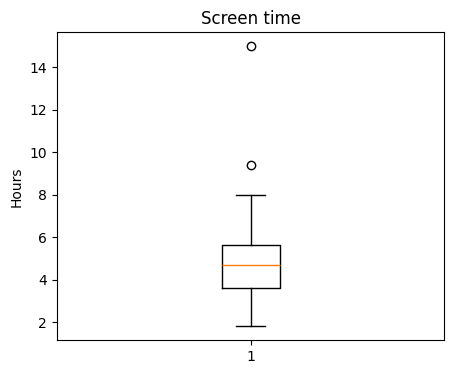

大於 10 小時： 1


In [14]:
# dropna 避免缺失值影響繪圖，資料並未從 df 刪除
plt.figure(figsize=(5, 4))
plt.boxplot(df["screen_time_hours"].dropna())
plt.title("Screen time")
plt.ylabel("Hours")
plt.show()
print("大於 10 小時：", (df["screen_time_hours"] > 10).sum())


## 延伸示範：分箱前後數據不變
相同資料用不同 bins 切分，外觀會不同。學生須檢查各箱人數加總與原本有效筆數是否一致，避免把分箱造成的視覺差異誤認為資料變化。


In [15]:
# numpy 的 histogram 回傳各箱人數及邊界；檢查加總是否一致
valid_scores = df["quiz_score"].dropna()
for bins in [5, 10]:
    counts, edges = np.histogram(valid_scores, bins=bins)
    print("分箱數", bins, "各箱人數", counts, "加總", counts.sum())
    assert counts.sum() == len(valid_scores)


分箱數 5 各箱人數 [ 5  9 20 18  8] 加總 60
分箱數 10 各箱人數 [ 3  2  3  6  9 11 13  5  5  3] 加總 60


## 本單元學習收束與 AI 使用紀錄

請學生先用自己的話解釋一個關鍵觀念，再指出一個執行結果及驗證方式。記錄：使用的提示詞、AI 回答中檢查或修改的地方、遇到的問題、修正後的證據與本資料限制。

**通用提示詞**：我是 Python 初學者，請逐步協助我完成上面的任務；每段程式加繁體中文註解，說明輸入、處理與輸出，提供兩項可實際執行的驗證，保留原始資料，不要虛構執行結果。


## 🎯 學生小任務 MA｜資料健檢與圖表
**涵蓋：**任務 1～4。這是需要獨立完成、可繳交的整合成果。

### 任務要求
使用 df，以程式列出資料形狀、各欄缺失數、超過 10 小時的筆數；再繪製 quiz_score 直方圖。用文字說明一項品質問題、一項圖表觀察及一項資料限制。不可修改 df。

### 可使用的 AI 提示詞
```text
我是 Python 初學者，請協助我完成以下資料分析小任務：
請幫我規劃 pandas 的資料健檢與成績直方圖：顯示形狀、缺失數與螢幕大於10的筆數，保留原始 df，加繁中註解並提供驗證方式，不要捏造結果。
請拆成小步驟，提供繁體中文教學註解、預期輸出應如何檢查，並提醒不能從這份模擬資料推論因果。
```

### 執行與交付
- 在下一個程式儲存格自行填入程式，先執行本 Notebook 上方的資料準備及必要 cell。若需要更多儲存格可以自行新增。
- 輸出應保留在 Notebook 中；在後面的文字區填寫實際數字與自己的解釋。
- **工具提示：**df.shape、df.isna()、布林篩選、plt.hist。
- 至少記錄一項實際檢查及一項資料限制。交付完成後的 `.ipynb`，含程式、輸出及 AI 使用紀錄。


=== 1. 資料形狀 ===
資料形狀 (列數, 欄數)： (60, 7)

=== 2. 缺失值統計 ===
student_id           0
department           0
sleep_hours          2
screen_time_hours    0
study_hours          0
attendance_rate      0
quiz_score           0
dtype: int64

=== 3. 條件篩選筆數 ===
quiz_score 大於 10 的筆數： 60

=== 4. 繪製直方圖 ===


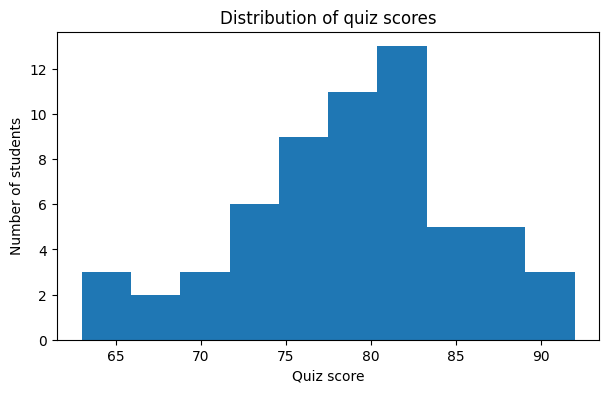

有效成績筆數： 60


In [16]:
import matplotlib.pyplot as plt
import pandas as pd

# 【資料健檢與視覺化一次執行】
# 註：此處確保不修改原始 df，所有操作皆為讀取與查詢

# 1. 顯示資料形狀 (列數, 欄數)
print("=== 1. 資料形狀 ===")
print("資料形狀 (列數, 欄數)：", df.shape)

# 2. 顯示各欄位缺失值數
print("\n=== 2. 缺失值統計 ===")
missing_counts = df.isnull().sum()
print(missing_counts)

# 3. 計算 quiz_score 大於 10 的筆數（不改變原始 df）
print("\n=== 3. 條件篩選筆數 ===")
score_gt_10_count = (df["quiz_score"] > 10).sum()
print("quiz_score 大於 10 的筆數：", score_gt_10_count)

# 4. 繪製 quiz_score 的直方圖（排除缺失值，分成 10 個區間）
print("\n=== 4. 繪製直方圖 ===")
plt.figure(figsize=(7, 4))
plt.hist(df["quiz_score"].dropna(), bins=10)
plt.title("Distribution of quiz scores")
plt.xlabel("Quiz score")
plt.ylabel("Number of students")
plt.show()

# 驗證有效成績筆數
print("有效成績筆數：", df["quiz_score"].count())

### ✍️ 小任務 MA｜結果與檢核（請雙擊填寫）
- 問題及使用的資料／欄位：使用 Pandas 對資料集 df 進行資料健檢與視覺化，使用欄位為 quiz_score
- 實際輸出與至少一項依據數字的觀察：輸出包含資料集的shape、各欄位的缺失值統計、筆數統計，以及有效成績的直方圖與總筆數。透過.dropna()與.count()掌握有效資料的數量，確保後續視覺化不會受到缺失值干擾
- 圖表或模型結果的解讀（依任務要求）：學生的整體表現相當集中且穩定，沒有出現明顯的兩極分化
- 資料品質、模擬資料或評估限制：資料中可能包含缺失值（NaN），需透過 dropna() 排除；描述性統計與直方圖僅能呈現現狀與分佈，無法據此推論因果關係
- 驗證方法與結果：以df["quiz_score"].count()驗證繪圖時的有效資料筆數是否正確，讓AI給我另一個版本並重新執行
- AI 工具、實際提示詞、人工修改與遇到的問題：Gemini Flash-Lite<br>1.我是 Python 初學者，請協助我完成以下資料分析小任務：
請幫我規劃 pandas 的資料健檢與成績直方圖：顯示形狀、缺失數與螢幕大於10的筆數，保留原始 df，加繁中註解並提供驗證方式，不要捏造結果。
請拆成小步驟，提供繁體中文教學註解、預期輸出應如何檢查，並提醒不能從這份模擬資料推論因果。<br>2.(發現我不喜歡小步驟)直接統整就好<br>3.(AI省略程式碼，直接描述各步驟的觀念)我是說程式碼 1次執行完規劃 pandas 的資料健檢與成績直方圖：顯示形狀、缺失數與螢幕大於10的筆數，保留原始 df，加繁中註解並提供驗證方式，不要捏造結果。<br>(確認與任務提示有相關)df.shape、df.isna()、布林篩選、plt.hist這有用到嗎
- 重新執行是否成功及環境或檔案需求：是，環境需支援 Python、Pandas 與 Matplotlib 庫，且記憶體中須已載入包含 quiz_score 欄位的 df 資料
